# Segmentation

Every scan of the old dataset is segmented by two tools: SynthSeg (FreeSurfer, CPU) and
WMH-SynthSeg (GPU). Both resample the input to 1 mm and write the label map on that grid.

## SynthSeg

All scans of the scan table. `mri_synthseg` reads a whole folder and loads its model
once per call, so the scans are grouped into 9 folders (3T highres, 3T lowres, 64mT × 3
modalities). SynthSeg resamples every input to 1 mm and writes the label map on that grid.

In [1]:
import os
import shutil
from pathlib import Path

import pandas as pd

from common import OLD_OUT, WORK, LOGS, THREADS, seg_path, fs

scans = pd.read_csv(OLD_OUT / 'scans.csv', keep_default_na=False)
scans['group'] = [f'3T_{a}_{m}' if f == '3T' else f'64mT_{m}' for f, a, m in zip(scans.fs, scans.acq, scans['mod'])]

SS = OLD_OUT / 'seg' / 'SynthSeg'
TABLES = SS / 'volumes'
TABLES.mkdir(parents=True, exist_ok=True)

### Segment and save

Per folder: link the scans into a staging folder, run `mri_synthseg`, then copy the label maps
and 1 mm images to the results folder (`{3T,64mT}/<subject>/[<session>/]`) and, last, the
folder's volume and QC tables. A folder whose volume table exists is finished and skipped.

In [2]:
for group, g in scans.groupby('group'):
    vol = TABLES / f'vol_{group}.csv'
    if vol.exists():
        continue
    print(f'=== {group}: {len(g)} scans')
    d_in, d_seg, d_res = (WORK / 'SynthSeg' / x / group for x in ('in', 'seg', 'res'))
    for d in (d_in, d_seg, d_res):
        shutil.rmtree(d, ignore_errors=True)
        d.mkdir(parents=True)
    for src in g.src:
        (d_in / Path(src).name).symlink_to(src)

    fs(f'mri_synthseg --i {d_in} --o {d_seg} --resample {d_res} '
       f'--vol {d_seg}/vol.csv --qc {d_seg}/qc.csv --robust --threads {THREADS}',
       log=LOGS / 'synthseg_old.log')

    for r in g.to_dict('records'):
        out = seg_path(OLD_OUT, 'SynthSeg', r)
        out.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy(d_seg / f"{r['scan']}_synthseg.nii.gz", out)
        res, = d_res.glob(f"{r['scan']}*.nii.gz")
        shutil.copy(res, out.parent / f"{r['scan']}_resampled.nii.gz")
    shutil.copy(d_seg / 'qc.csv', TABLES / f'qc_{group}.csv')
    shutil.copy(d_seg / 'vol.csv', vol)

#### What segmentation produced

| Level | File | Location | What it is |
|---|---|---|---|
| Per scan | `<scan>_synthseg.nii.gz` | `lfbook/results/old/seg/SynthSeg/{3T,64mT}/<sub>/[<ses>/]` | Label map, 1 mm |
| | `<scan>_resampled.nii.gz` | same folder as above | Raw image resampled to 1 mm, aligned with the label map |
| Per group | `vol_<group>.csv`, `qc_<group>.csv` | `lfbook/results/old/seg/SynthSeg/volumes/` | Volumes and QC scores of one group |
| Log | `synthseg_old.log` | `lfbook/results/logs/` | Run log |

In [3]:
from datetime import datetime

rows = []
for group, g in scans.groupby('group'):
    outs = [seg_path(OLD_OUT, 'SynthSeg', r) for r in g.to_dict('records')]
    vol = TABLES / f'vol_{group}.csv'
    rows.append({
        'group': group,
        'scans': len(g),
        'label maps': sum(o.exists() for o in outs),
        '1 mm images': sum((o.parent / f'{s}_resampled.nii.gz').exists() for o, s in zip(outs, g.scan)),
        'qc table': (TABLES / f'qc_{group}.csv').exists(),
        'finished': datetime.fromtimestamp(vol.stat().st_mtime).strftime('%Y-%m-%d %H:%M') if vol.exists() else 'no',
    })
pd.DataFrame(rows)

,group,scans,label maps,1 mm images,qc table,finished
0,3T_highres_FLAIR,11,11,11,True,2026-10-07 00:21
1,3T_highres_T1w,11,11,11,True,2026-10-07 00:31
2,3T_highres_T2w,11,11,11,True,2026-10-07 00:42
3,3T_lowres_FLAIR,11,11,11,True,2026-10-07 00:51
4,3T_lowres_T1w,11,11,11,True,2026-10-07 01:00
5,3T_lowres_T2w,11,11,11,True,2026-10-07 01:09
6,64mT_FLAIR,21,21,21,True,2026-10-07 01:27
7,64mT_T1w,20,20,20,True,2026-10-07 01:44
8,64mT_T2w,20,20,20,True,2026-10-07 02:02


#### Talk about Influence of Resampling

SynthSeg first resamples every input image to 1 × 1 × 1 mm and segments the resampled image, so the label map is on the 1 mm grid, not on the raw image's grid. The resampled image is saved as `<scan>_resampled.nii.gz`.

Below: sub-0015, 64mT T1w. Top row: raw image; bottom row: resampled image; axial, coronal and sagittal slices through the same point. The 5 mm slices show as steps in the coronal and sagittal views; resampling smooths the steps but adds no detail.

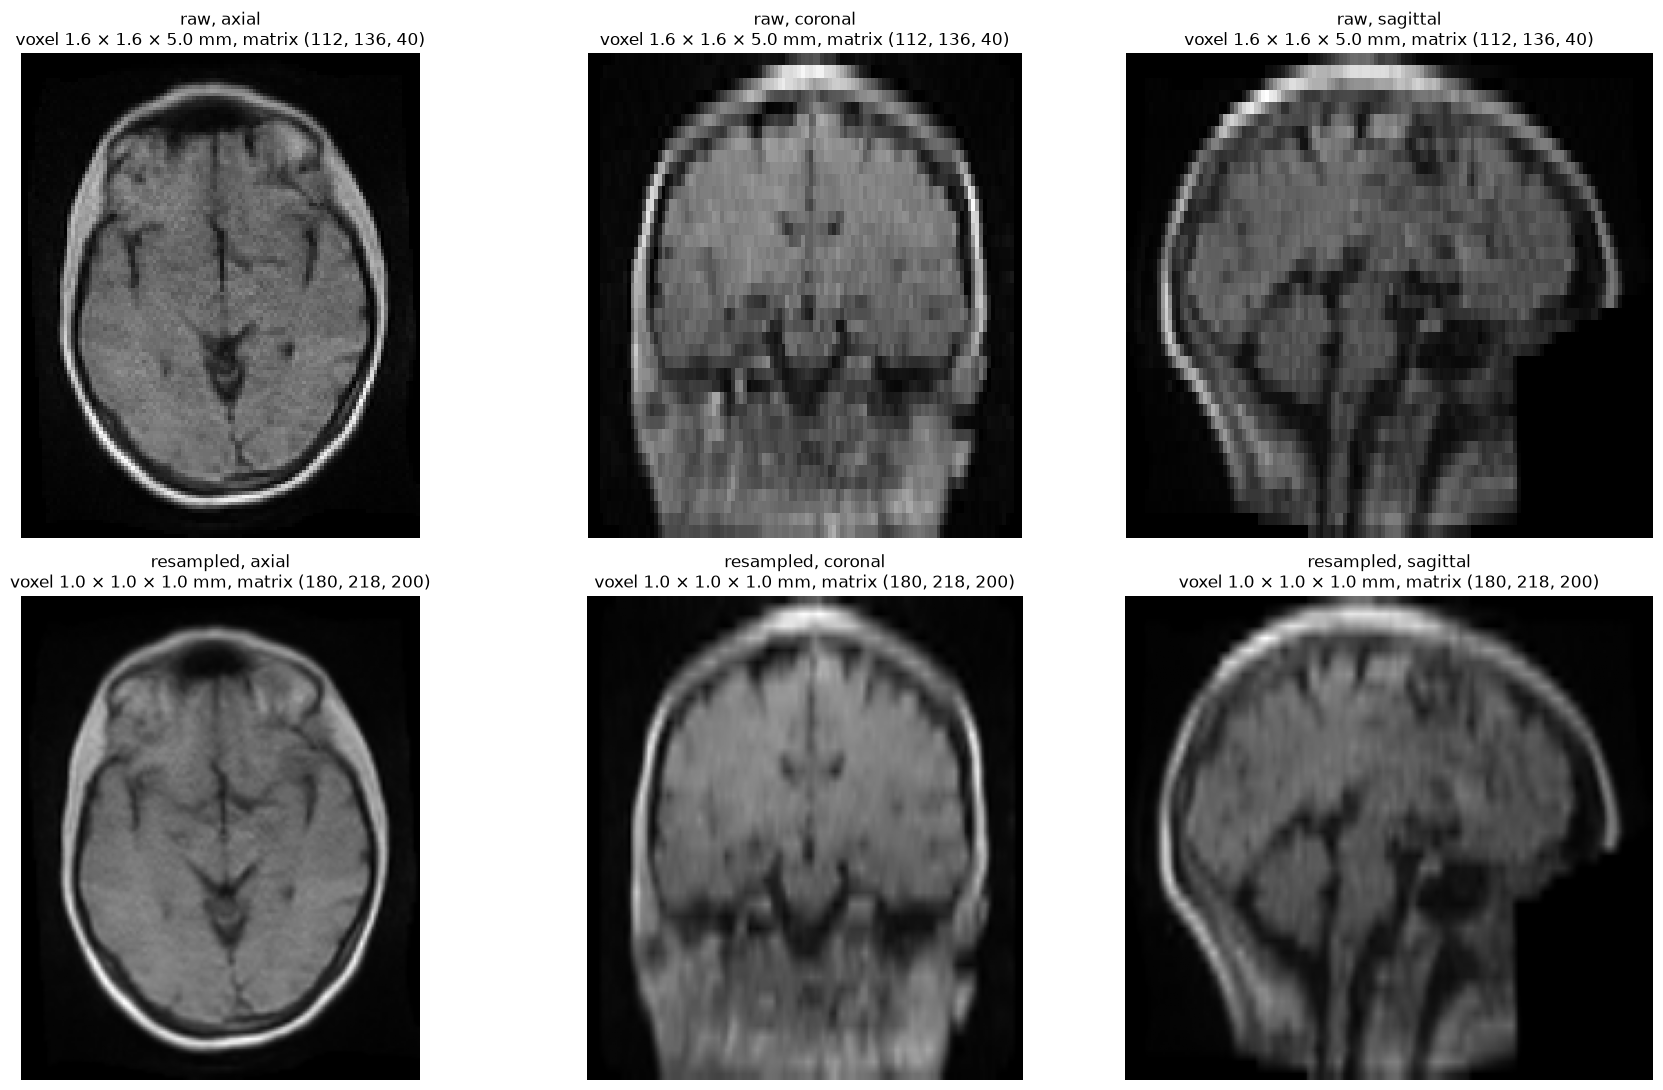

In [4]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

SCAN = 'sub-0015_ses-01_run-1_T1w'   # not cut off at the bottom (see Chapter 05)
POINT = (0.5, 0.5, 0.5)              # where to cut, as a fraction of the raw image: (left-right, back-front, bottom-top)

row = scans[scans.scan == SCAN].iloc[0]
raw = nib.as_closest_canonical(nib.load(row['src']))
res = nib.as_closest_canonical(nib.load(seg_path(OLD_OUT, 'SynthSeg', row).parent / f'{SCAN}_resampled.nii.gz'))
xyz = raw.affine @ [*(np.array(POINT) * (np.array(raw.shape[:3]) - 1)), 1]   # the point in scanner coordinates

VIEWS = {'axial': (2, (0, 1)), 'coronal': (1, (0, 2)), 'sagittal': (0, (1, 2))}   # cut axis, shown axes
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax_row, (img, name) in zip(axes, [(raw, 'raw'), (res, 'resampled')]):
    data = img.get_fdata()
    vox = img.header.get_zooms()[:3]
    ijk = np.round(np.linalg.inv(img.affine) @ xyz)[:3].astype(int)      # same point in this image
    for ax, (view, (cut, (a, b))) in zip(ax_row, VIEWS.items()):
        sl = [slice(None)] * 3
        sl[cut] = int(np.clip(ijk[cut], 0, data.shape[cut] - 1))
        ax.imshow(data[tuple(sl)].T, cmap='gray', origin='lower', aspect=vox[b] / vox[a])
        ax.set_title(f'{name}, {view}\nvoxel {vox[0]:.1f} × {vox[1]:.1f} × {vox[2]:.1f} mm, matrix {data.shape}')
        ax.axis('off')
plt.tight_layout()
plt.show()

The steps matter more after registration, which rotates the 64mT scan onto the 3T grid. Moved without interpolation (nearest neighbour: each new voxel copies the closest old voxel), every 5 mm slice stays a 5 mm block; the blocks are now tilted, so their edges cross the 3T grid at an angle and show as oblique stair-step lines. With interpolation (trilinear), each new voxel is a weighted mean of the neighbouring slices, so the steps blend into a smooth edge; as above, no detail is added. The comparison on a registered pair is in {ref}`Chapter 04 <reg-interpolation>`.

### Merge the tables

The 9 volume tables and 9 QC tables are stacked into one table each, with the scan-table columns
added.

In [5]:
def stack(kind):
    d = pd.concat([pd.read_csv(f) for f in sorted(TABLES.glob(f'{kind}_*.csv'))], ignore_index=True)
    d = d.rename(columns={d.columns[0]: 'scan'})
    d['scan'] = (d.scan.astype(str).map(os.path.basename)
                 .str.replace(r'\.nii(\.gz)?$', '', regex=True).str.replace(r'_synthseg$', '', regex=True))
    return scans.drop(columns=['src', 'group']).merge(d, on='scan', validate='1:1')


for kind, name in [('vol', 'volumes_wide.csv'), ('qc', 'qc_all.csv')]:
    t = stack(kind)
    assert len(t) == len(scans), f'{name}: {len(t)} rows, expected {len(scans)}'
    t.to_csv(SS / name, index=False)

missing = [r['scan'] for r in scans.to_dict('records') if not seg_path(OLD_OUT, 'SynthSeg', r).exists()]
assert not missing, f'not segmented: {missing}'
print(f"SynthSeg: {len(scans)} scans -> {SS}/volumes_wide.csv, qc_all.csv")

SynthSeg: 127 scans -> /home/jovyan/neurodesktop-storage/lfbook/results/old/seg/SynthSeg/volumes_wide.csv, qc_all.csv


## WMH-SynthSeg

All scans of the scan table, on the Neurodesk GPU (NVIDIA A40). Code from commit `2bf9a42`, with
two patches: the model path (hard-coded to `/app/models`) points to the model folder in
`config.yml`, and `weights_only=False` for PyTorch ≥ 2.6. The model weights (790 MB) are
downloaded once. No `--crop` (it had an out-of-bounds bug), so the full field of view goes
through the network at once.

In [6]:
import subprocess
import sys
import time

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import torch

from common import P, sh

WMH = OLD_OUT / 'seg' / 'WMH_SynthSeg'
WMH_REPO, MODEL = P['wmh_code'], P['wmh_model']
INF = WMH_REPO / 'WMHSynthSeg' / 'inference.py'
COMMIT = '2bf9a42'

if not INF.exists():
    sh(f'git clone -q https://github.com/lasopablo/freesurfer-freesurfer-dev-mri_WMHsynthseg.git {WMH_REPO} '
       f'&& git -C {WMH_REPO} checkout -q {COMMIT}')
    sh(f"""sed -i "s#'/app/models'#'{MODEL.parent}'#" {INF}""")
    sh(f'sed -i "s/torch.load(model_file, map_location=device)/'
       f'torch.load(model_file, map_location=device, weights_only=False)/" {INF}')
if not (MODEL.exists() and MODEL.stat().st_size > 0):
    MODEL.parent.mkdir(parents=True, exist_ok=True)
    sh(f'wget -q -c -O {MODEL} https://ftp.nmr.mgh.harvard.edu/pub/dist/lcnpublic/dist/WMH-SynthSeg/{MODEL.name}')
sh(f"git -C {WMH_REPO} log -1 --format='commit %h  %ad'")
sh(f"grep -n 'model_file = \\|torch.load(' {INF}")

commit 2bf9a42  Sat Jun 1 15:28:41 2024 -0400
94:    model_file = os.path.join('/home/jovyan/neurodesktop-storage/lfbook/wmh_model', 'WMH-SynthSeg_v10_231110.pth')
127:        checkpoint = torch.load(model_file, map_location=device, weights_only=False)


### Resampling to 1 mm

Before the network sees a scan, `inference.py` does four things:

1. reorders the axes to R, A, S (only swaps and flips, no interpolation);
2. divides the image by its maximum;
3. resamples it to 1 mm with `myzoom_torch` (in `utils.py`);
4. pads it with zeros to a multiple of 32.

`myzoom_torch` works per axis with `factor = voxel size / 1 mm`: the new grid has
`round(size × factor)` voxels, and each new voxel is a linear interpolation between the two
nearest original voxels (trilinear over the three axes). There is no smoothing before it.

The label map and the volumes are written on this 1 mm grid, not on the grid of the input scan.

The table lists the voxel size and grid of every scan in R × A × S order, as `inference.py` sees
them, with the 1 mm grid and the padded grid the network runs on.

In [7]:
def grid_ras(src):
    """Voxel size (mm) and grid size in R, A, S order, as inference.py sees them (header only)."""
    img = nib.load(src)
    axis = nib.io_orientation(img.affine)[:, 0].astype(int)   # input axis i -> RAS axis axis[i]
    vox, shape = np.zeros(3), np.zeros(3, int)
    vox[axis], shape[axis] = img.header.get_zooms()[:3], img.shape[:3]
    return vox, shape


rows = []
for r in scans.to_dict('records'):
    vox, shape = grid_ras(r['src'])
    new = np.round(shape * vox).astype(int)                    # factor = voxel size / 1 mm
    pad = (np.ceil(new / 32) * 32).astype(int)
    rows.append(dict(fs=r['fs'], acq=r['acq'], mod=r['mod'],
                     voxel_mm=' × '.join(f'{x:.2f}' for x in vox),
                     grid=' × '.join(map(str, shape)),
                     grid_1mm=' × '.join(map(str, new)),
                     padded=' × '.join(map(str, pad))))
grids = (pd.DataFrame(rows).groupby(list(rows[0]), sort=False).size().rename('scans')
         .reset_index().sort_values(['fs', 'acq', 'mod'], ignore_index=True))
grids

,fs,acq,mod,voxel_mm,grid,grid_1mm,padded,scans
0,3T,highres,FLAIR,0.43 × 0.43 × 5.50,512 × 512 × 27,220 × 220 × 148,224 × 224 × 160,11
1,3T,highres,T1w,0.90 × 0.49 × 0.49,150 × 448 × 448,135 × 220 × 220,160 × 224 × 224,1
2,3T,highres,T1w,0.49 × 0.49 × 1.00,448 × 448 × 156,220 × 220 × 156,224 × 224 × 160,10
3,3T,highres,T2w,0.22 × 0.22 × 3.00,1008 × 1008 × 50,220 × 220 × 150,224 × 224 × 160,11
4,3T,lowres,FLAIR,1.38 × 1.38 × 5.50,160 × 160 × 28,220 × 220 × 154,224 × 224 × 160,11
5,3T,lowres,T1w,1.38 × 1.38 × 5.00,160 × 160 × 31,220 × 220 × 155,224 × 224 × 160,11
6,3T,lowres,T2w,1.38 × 1.38 × 5.00,160 × 160 × 31,220 × 220 × 155,224 × 224 × 160,11
7,64mT,-,FLAIR,1.70 × 1.70 × 5.00,106 × 130 × 40,180 × 221 × 200,192 × 224 × 224,19
8,64mT,-,FLAIR,1.70 × 1.70 × 5.00,106 × 130 × 30,180 × 221 × 150,192 × 224 × 160,1
9,64mT,-,FLAIR,0.85 × 0.85 × 5.00,212 × 260 × 40,180 × 221 × 200,192 × 224 × 224,1


Two things change the image:

- **Thick slices.** Almost every scan has 3–5.5 mm slices. Resampling fills the gap with 2–4
  new slices that are only blends of the two real ones; no detail is added.
- **Fine in-plane voxels.** 3T highres scans (0.22–0.49 mm) are shrunk 2–4.5 times. Linear
  interpolation uses only the two nearest voxels and skips the ones in between, so fine detail
  is lost and edges become jagged.

64mT scans (1.6–1.7 mm in-plane) are slightly enlarged in-plane: smoother, but no new detail.

#### Examples

Five scans of `sub-0015`: two HF (3T highres T2w, FLAIR) and three LF (64mT T1w, T2w, FLAIR),
before and after the resampling above. Each panel shows the whole head (220 mm window), with
every voxel drawn as a block of its real size. Left: axial; right: coronal, where the slice
thickness shows.

/home/jovyan/conda-envs/lfbook/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


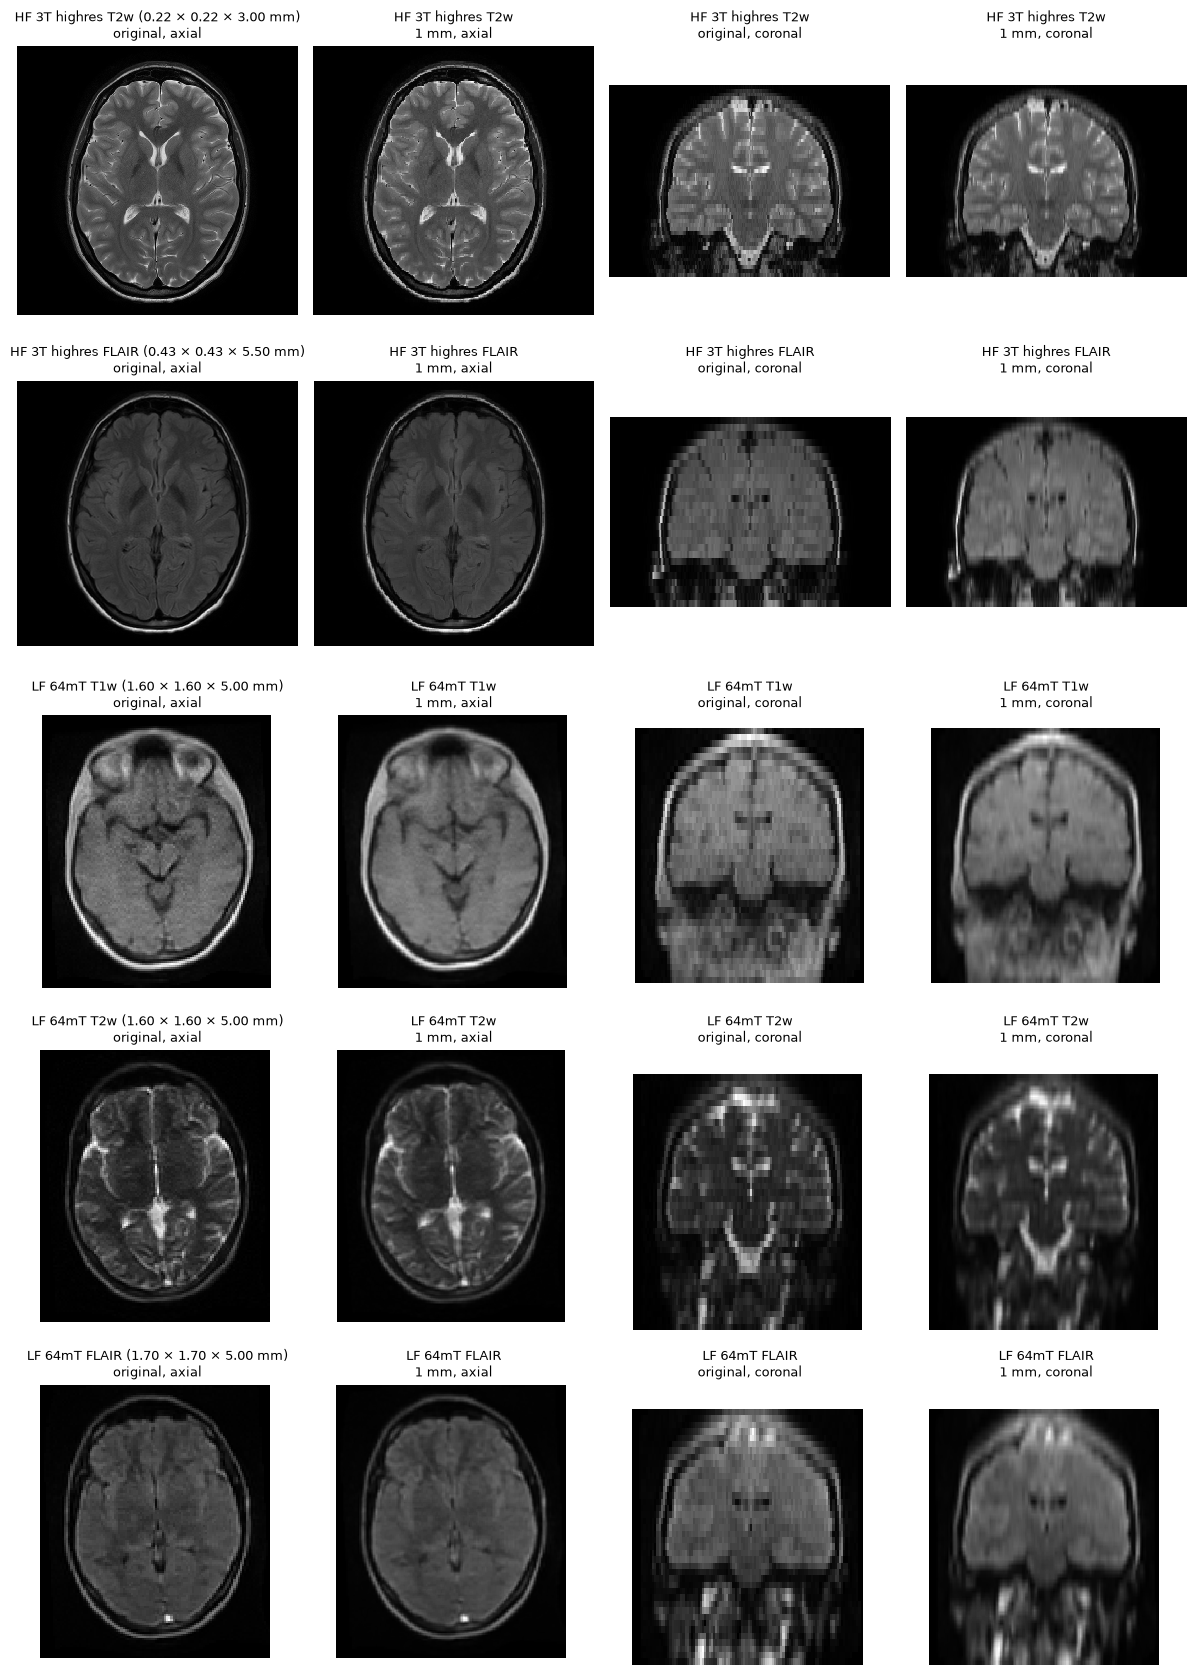

In [8]:
sys.path.insert(0, str(INF.parent))
from utils import MRIread, align_volume_to_ref, myzoom_torch


def to_1mm(src):
    """The first steps of inference.py: reorient to RAS, scale to [0, 1], resample to 1 mm."""
    image, aff = MRIread(src)
    x = torch.tensor(np.squeeze(image).astype(float))
    x, aff2 = align_volume_to_ref(x, aff, aff_ref=np.eye(4), return_aff=True, n_dims=3)
    x = x / torch.max(x)
    factors = np.sqrt(np.sum(aff2 ** 2, axis=0))[:-1]          # voxel size / 1 mm
    return x.numpy(), myzoom_torch(x, factors, device='cpu').numpy(), factors


def show(ax, img, vox, start, centre, title, half=110):
    """220 mm window around `centre`; each voxel is drawn as a block of its real size.
    Positions in mm along the original grid; `start` = position of the first voxel."""
    lo = np.array(start) - 0.5 * np.array(vox)
    ax.imshow(img.T, cmap='gray', origin='lower', interpolation='nearest', vmin=0, vmax=img.max(),
              extent=(lo[0], lo[0] + img.shape[0] * vox[0], lo[1], lo[1] + img.shape[1] * vox[1]))
    ax.set_xlim(centre[0] - half, centre[0] + half)
    ax.set_ylim(centre[1] - half, centre[1] + half)
    ax.set_title(title, fontsize=9)
    ax.axis('off')


EXAMPLES = ['sub-0015_acq-highres_T2w', 'sub-0015_acq-highres_FLAIR',                        # HF
            'sub-0015_ses-01_run-1_T1w', 'sub-0015_ses-01_run-1_T2w', 'sub-0015_ses-01_run-1_FLAIR']  # LF
EXAMPLES = [s for s in EXAMPLES if s in set(scans.scan)]                                 # test run
fig, axes = plt.subplots(len(EXAMPLES), 4, figsize=(12, 3.4 * len(EXAMPLES)), squeeze=False)
for ax, scan in zip(axes, EXAMPLES):
    r = scans.set_index('scan').loc[scan]
    name = f"HF 3T {r['acq']} {r['mod']}" if r['fs'] == '3T' else f"LF 64mT {r['mod']}"
    orig, new, f = to_1mm(r['src'])
    c = np.array([np.average(np.arange(n), weights=new.sum(axis=tuple(a for a in range(3) if a != d)))
                  for d, n in enumerate(new.shape)])                # brain centre (intensity), 1 mm grid
    i, j, k = np.round(c).astype(int)
    s0 = 0.5 - 0.5 * f                                            # first 1 mm voxel, in mm (myzoom_torch)
    c = c + s0
    ko, jo = np.round((np.array([k, j]) + 0.5) / f[[2, 1]] - 0.5).astype(int)   # nearest original slice
    vox = ' × '.join(f'{v:.2f}' for v in f)
    show(ax[0], orig[:, :, ko], f[[0, 1]], [0, 0], c[[0, 1]], f'{name} ({vox} mm)\noriginal, axial')
    show(ax[1], new[:, :, k], [1, 1], s0[[0, 1]], c[[0, 1]], f'{name}\n1 mm, axial')
    show(ax[2], orig[:, jo, :], f[[0, 2]], [0, 0], c[[0, 2]], f'{name}\noriginal, coronal')
    show(ax[3], new[:, j, :], [1, 1], s0[[0, 2]], c[[0, 2]], f'{name}\n1 mm, coronal')
fig.tight_layout()

### Segment and save

Scans without a label map are linked into one staging folder, and `inference.py` runs once on
it, so the model loads once. Label maps are moved to the results folder
(`{3T,64mT}/<subject>/[<session>/]`) and their volumes added to `volumes_main.csv`.
`inference.py` does not stop when a scan fails; those messages are shown if any scan is left
without a label map. A 3T scan takes about 12 s and up to 41 of the 45 GB GPU memory.

In [9]:
LOG = LOGS / 'wmh_synthseg_old.log'
WMH.mkdir(parents=True, exist_ok=True)
todo = [r for r in scans.to_dict('records') if not seg_path(OLD_OUT, 'WMH_SynthSeg', r).exists()]
if todo:
    print(f'{len(todo)} scans to segment')
    # GPU only needed here; with all label maps present the chapter runs on CPU.
    # is_available() does not start CUDA in this kernel, so the whole GPU stays free for inference.py
    assert torch.cuda.is_available(), 'no GPU: start Neurodesk on the A40 server'
    sh('nvidia-smi --query-gpu=name,memory.total --format=csv,noheader')
    stage, segout = WORK / 'WMH_SynthSeg' / 'stage', WORK / 'WMH_SynthSeg' / 'segout'
    for d in (stage, segout):
        shutil.rmtree(d, ignore_errors=True)
        d.mkdir(parents=True)
    for r in todo:
        (stage / f"{r['scan']}.nii.gz").symlink_to(r['src'])

    # expandable_segments reduces GPU memory fragmentation
    sh(f'PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True {sys.executable} inference.py '
       f'--i {stage} --o {segout} --csv_vols {segout}/vols.csv --device cuda',
       cwd=INF.parent, log=LOG, show=False)

    for r in todo:
        seg = segout / f"{r['scan']}_seg.nii.gz"
        if seg.exists():
            out = seg_path(OLD_OUT, 'WMH_SynthSeg', r)
            out.parent.mkdir(parents=True, exist_ok=True)
            shutil.move(seg, out)

    # volume table: scan-table columns + volumes, merged with earlier results
    vols = pd.read_csv(segout / 'vols.csv')
    vols['scan'] = vols.pop('Input-file').map(lambda p: os.path.basename(p)[:-len('_seg.nii.gz')])
    tidy = pd.DataFrame(todo).drop(columns=['src', 'group']).merge(vols, on='scan')
    dst = WMH / 'volumes_main.csv'
    if dst.exists():
        tidy = pd.concat([pd.read_csv(dst, keep_default_na=False), tidy],
                         ignore_index=True).drop_duplicates('scan', keep='last')
    tidy.sort_values(['fs', 'sub', 'mod', 'acq']).to_csv(dst, index=False)

    commit = subprocess.run(['git', '-C', str(WMH_REPO), 'log', '-1', '--format=%h %ad'],
                            capture_output=True, text=True).stdout.strip()
    gpu = subprocess.run(['nvidia-smi', '--query-gpu=name', '--format=csv,noheader'],
                         capture_output=True, text=True).stdout.strip()
    (WMH / 'PROVENANCE.txt').write_text(f"""WMH-SynthSeg results, old dataset ({len(scans)} scans)
Computed on Neurodesk, Chapter 03 of the book; written {time.strftime('%Y-%m-%d %H:%M %Z')}
GPU: {gpu} | torch {torch.__version__}
Code: lasopablo/freesurfer-freesurfer-dev-mri_WMHsynthseg, commit {commit}
Model: {MODEL.name} ({MODEL.stat().st_size / 1e6:.0f} MB)
Settings: --device cuda, no --crop
""")

missing = [r['scan'] for r in scans.to_dict('records') if not seg_path(OLD_OUT, 'WMH_SynthSeg', r).exists()]
if missing:
    sh(f"grep 'error occurred' {LOG} | sort | uniq -c || true")
    raise RuntimeError(f'{len(missing)} scans not segmented: {missing}')
no_row = sorted(set(scans.scan) - set(pd.read_csv(WMH / 'volumes_main.csv').scan))
assert not no_row, f'missing rows in volumes_main.csv: {no_row}'
print((WMH / 'PROVENANCE.txt').read_text())
print(f'WMH-SynthSeg: {len(scans)} scans -> {WMH}')

WMH-SynthSeg results, old dataset (127 scans)
Computed on Neurodesk, Chapter 03 of the book; written 2026-10-14 03:18 UTC
GPU: NVIDIA A40 | torch 2.14.1+cu130
Code: lasopablo/freesurfer-freesurfer-dev-mri_WMHsynthseg, commit 2bf9a42 Sat Jun 1 15:28:41 2024 -0400
Model: WMH-SynthSeg_v10_231110.pth (791 MB)
Settings: --device cuda, no --crop

WMH-SynthSeg: 127 scans -> /home/jovyan/neurodesktop-storage/lfbook/results/old/seg/WMH_SynthSeg


#### What segmentation produced

| Level | File | Location | What it is |
|---|---|---|---|
| Per scan | `<scan>_WMHseg.nii.gz` | `lfbook/results/old/seg/WMH_SynthSeg/{3T,64mT}/<sub>/[<ses>/]` | Label map, 1 mm. Each voxel holds a label number, e.g. 77 = WMH, 2 = left white matter |
| All scans | `volumes_main.csv` | `lfbook/results/old/seg/WMH_SynthSeg/` | One row per scan: scan info, intracranial volume and the volume of 33 labels in mm³ |
| | `PROVENANCE.txt` | same folder as above | GPU, PyTorch version, code commit, model file, settings |
| Log | `wmh_synthseg_old.log` | `lfbook/results/logs/` | Everything `inference.py` printed; used to find scans that failed |

Not produced: QC scores (WMH-SynthSeg has no QC option, unlike SynthSeg).

In [10]:
v = pd.read_csv(WMH / 'volumes_main.csv', keep_default_na=False)
rows = []
for group, g in scans.groupby('group'):
    rows.append({
        'group': group,
        'scans': len(g),
        'label maps': sum(seg_path(OLD_OUT, 'WMH_SynthSeg', r).exists() for r in g.to_dict('records')),
        'table rows': g.scan.isin(v.scan).sum(),
    })
pd.DataFrame(rows)

,group,scans,label maps,table rows
0,3T_highres_FLAIR,11,11,11
1,3T_highres_T1w,11,11,11
2,3T_highres_T2w,11,11,11
3,3T_lowres_FLAIR,11,11,11
4,3T_lowres_T1w,11,11,11
5,3T_lowres_T2w,11,11,11
6,64mT_FLAIR,21,21,21
7,64mT_T1w,20,20,20
8,64mT_T2w,20,20,20
